# Chemistry Grapn Neural Network (GNN) Example
We will apply a GCN and a edge-conditioned MPNN to the delaney dataset

# Install Packages
Only run if you do not have packages installed

In [ ]:
%pip install rdkit
%pip install pandas
%pip install scikit-learn
%pip install matplotlib
%pip install torch torchvision torchaudio torch-geometric

# Load data and set seed

In [1]:

import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from rdkit import Chem

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, NNConv, global_mean_pool


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

df = pd.read_csv("delaney.csv")



C:\Users\allis\anaconda3\envs\AI_class\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


# Methods for getting atom and bond features

In [4]:
#get a one hot encoding of the value, with the final category representing other
def one_hot_with_other(value, choices):
    result = [0.0] * (len(choices) + 1)

    if value in choices:
        result[choices.index(value)] = 1.0
    else:
        result[-1] = 1.0

    return result

# here is alist of all values that will be accepted for different atom properties
ATOM_TYPES = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]

DEGREES = [0, 1, 2, 3, 4, 5]

FORMAL_CHARGES = [-2, -1, 0, 1, 2]

HYBRIDIZATIONS = [
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]

NUM_HYDROGENS = [0, 1, 2, 3, 4]

#get the one hot tom features
def atom_features(atom):
    features = []

    features += one_hot_with_other(
        atom.GetSymbol(), ATOM_TYPES
    )

    features += one_hot_with_other(
        atom.GetDegree(), DEGREES
    )

    features += one_hot_with_other(
        atom.GetFormalCharge(), FORMAL_CHARGES
    )

    features += one_hot_with_other(
        atom.GetHybridization(), HYBRIDIZATIONS
    )

    features.append(float(atom.GetIsAromatic()))
    features.append(float(atom.IsInRing()))

    features += one_hot_with_other(
        atom.GetTotalNumHs(), NUM_HYDROGENS
    )

    return features

#do the same thing for bond features
BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC,
]

BOND_STEREO = [
    Chem.rdchem.BondStereo.STEREONONE,
    Chem.rdchem.BondStereo.STEREOANY,
    Chem.rdchem.BondStereo.STEREOZ,
    Chem.rdchem.BondStereo.STEREOE,
    Chem.rdchem.BondStereo.STEREOCIS,
    Chem.rdchem.BondStereo.STEREOTRANS,
]

#method gets one hot encoding for categorical features and binary value for binary features
def bond_features(bond):
    features = []

    features += one_hot_with_other(
        bond.GetBondType(), BOND_TYPES
    )

    features.append(float(bond.GetIsConjugated()))
    features.append(float(bond.IsInRing()))

    features += one_hot_with_other(
        bond.GetStereo(), BOND_STEREO
    )

    return features

#calculate sizes for node and edge features with an example molecule
NODE_DIM = len(
    atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0))
)

EDGE_DIM = len(
    bond_features(Chem.MolFromSmiles("CC").GetBondWithIdx(0))
)

# Create graphs for pytorch

In [5]:
#converta smiles string to a graphy
def smiles_to_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # Atom features to pytorch tensor
    x = torch.tensor(
        [atom_features(atom) for atom in mol.GetAtoms()],
        dtype=torch.float32
    )

    edge_indices = []
    edge_attributes = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        features = bond_features(bond)

        # Both directions for each undirected chemical bond
        edge_indices.extend([[i, j], [j, i]])
        edge_attributes.extend([features, features])

    if edge_indices:
        edge_index = torch.tensor(
            edge_indices, dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attributes, dtype=torch.float32
        )
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, EDGE_DIM), dtype=torch.float32)
    
    #make pytorch tensor for target property
    y = torch.tensor([target], dtype=torch.float32)

    return Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=y
    )


graphs = []

#make graphs with smiles and prediction target column
for smiles, target in zip(df["SMILES"], df["measured log(solubility:mol/L)"]):
    graph = smiles_to_graph(smiles, target)

    if graph is not None:
        graphs.append(graph)

print("Graphs created:", len(graphs))
print("First graph:", graphs[0])


Graphs created: 1144
First graph: Data(x=[6, 37], edge_index=[2, 10], edge_attr=[10, 14], y=[1])


# Split data to training and validation

In [6]:
indices = np.arange(len(graphs))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED
)

train_graphs = [graphs[i] for i in train_idx]
val_graphs = [graphs[i] for i in val_idx]


train_loader = DataLoader(
    train_graphs, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_graphs, batch_size=32, shuffle=False
)


print("Training:", len(train_graphs))
print("Validation:", len(val_graphs))


Training: 915
Validation: 229


# Graph Convolutional Network (GCN)

In [7]:

class GCNModel(nn.Module):
    def __init__(self, node_dim, hidden_dim=32):
        super().__init__()
        #two layers of graph convolution
        self.conv1 = GCNConv(node_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        
        #one hidden fully connected layer before output layer
        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        
        #This is another way to apply ReLU activation between GCN layers
        x = torch.relu(self.conv1(x, edge_index))
        x = torch.relu(self.conv2(x, edge_index))

        # Convert atom embeddings to molecule embeddings
        x = global_mean_pool(x, data.batch)

        return self.regressor(x).view(-1)


# Edge conditioned MPNN

In [8]:

class EdgeMPNNModel(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=32):
        super().__init__()

        # Edge network for the first convolution:
        # generates node_dim x hidden_dim matrices
        edge_nn1 = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, node_dim * hidden_dim)
        )

        # Edge network for the second convolution:
        # generates hidden_dim x hidden_dim matrices
        edge_nn2 = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim * hidden_dim)
        )

        self.conv1 = NNConv(
            in_channels=node_dim,
            out_channels=hidden_dim,
            nn=edge_nn1,
            aggr="add"
        )

        self.conv2 = NNConv(
            in_channels=hidden_dim,
            out_channels=hidden_dim,
            nn=edge_nn2,
            aggr="add"
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr

        x = torch.relu(
            self.conv1(x, edge_index, edge_attr)
        )

        x = torch.relu(
            self.conv2(x, edge_index, edge_attr)
        )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).view(-1)


# Train models

In [10]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    n_samples = 0

    for batch in loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        predictions = model(batch)
        targets = batch.y.view(-1)

        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()

    predictions = []
    targets = []

    for batch in loader:
        batch = batch.to(device)

        pred = model(batch)
        target = batch.y.view(-1)

        predictions.append(pred.cpu().numpy())
        targets.append(target.cpu().numpy())

    predictions = np.concatenate(predictions)
    targets = np.concatenate(targets)

    rmse = np.sqrt(mean_squared_error(targets, predictions))
    mae = mean_absolute_error(targets, predictions)
    r2 = r2_score(targets, predictions)

    return {
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "predictions": predictions,
        "targets": targets
    }


def train_model(
    model,
    train_loader,
    val_loader,
    max_epochs=300,
    learning_rate=0.001
):
    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    criterion = nn.MSELoss()

    history = {"train_loss": [], "val_rmse": []}

    for epoch in range(max_epochs):
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion
        )

        val_results = evaluate(model, val_loader)
        val_rmse = val_results["rmse"]

        history["train_loss"].append(train_loss)
        history["val_rmse"].append(val_rmse)


    return model, history


#create and train models
HIDDEN_DIM = 32

gcn_model = GCNModel(
    node_dim=NODE_DIM,
    hidden_dim=HIDDEN_DIM
)

mpnn_model = EdgeMPNNModel(
    node_dim=NODE_DIM,
    edge_dim=EDGE_DIM,
    hidden_dim=HIDDEN_DIM
)

#compare number of parameters, MPNN will have more because it has parameters to learn edge conditioning
print("GCN parameters:", sum(
    p.numel() for p in gcn_model.parameters()
))

print("MPNN parameters:", sum(
    p.numel() for p in mpnn_model.parameters()
))


print("\nTraining GCN:")
gcn_model, gcn_history = train_model(
    gcn_model, train_loader, val_loader
)

print("\nTraining edge-conditioned MPNN:")
mpnn_model, mpnn_history = train_model(
    mpnn_model, train_loader, val_loader
)




GCN parameters: 3361
MPNN parameters: 77185

Training GCN:

Training edge-conditioned MPNN:


# Plot training progress

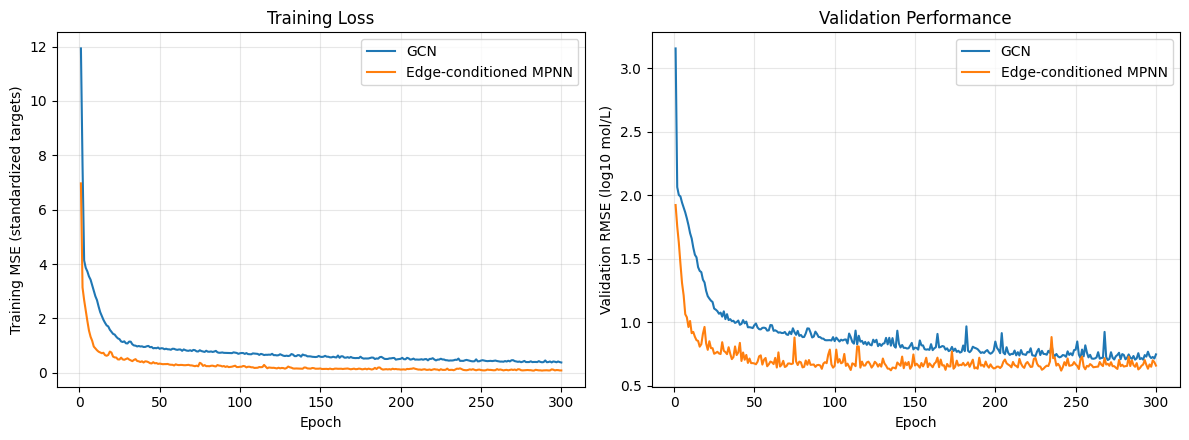

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

histories = {
    "GCN": gcn_history,
    "Edge-conditioned MPNN": mpnn_history
}

# Training MSE loss
for name, history in histories.items():
    axes[0].plot(
        range(1, len(history["train_loss"]) + 1),
        history["train_loss"],
        label=name
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training MSE (standardized targets)")
axes[0].set_title("Training Loss")
axes[0].legend()

# Validation RMSE
for name, history in histories.items():
    axes[1].plot(
        range(1, len(history["val_rmse"]) + 1),
        history["val_rmse"],
        label=name
    )

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation RMSE (log10 mol/L)")
axes[1].set_title("Validation Performance")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Plot true vs predicted for validation set

                   Model   RMSE    MAE     R2
0                    GCN  0.748  0.558  0.872
1  Edge-conditioned MPNN  0.659  0.483  0.900


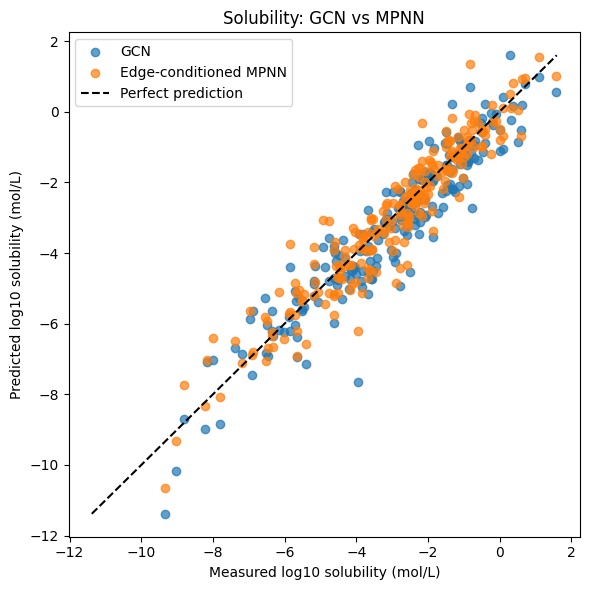

In [12]:

gcn_results = evaluate(gcn_model, val_loader)
mpnn_results = evaluate(mpnn_model, val_loader)

results_df = pd.DataFrame({
    "Model": ["GCN", "Edge-conditioned MPNN"],
    "RMSE": [
        gcn_results["rmse"],
        mpnn_results["rmse"]
    ],
    "MAE": [
        gcn_results["mae"],
        mpnn_results["mae"]
    ],
    "R2": [
        gcn_results["r2"],
        mpnn_results["r2"]
    ]
})

print(results_df.round(3))


plt.figure(figsize=(6, 6))

plt.scatter(
    gcn_results["targets"],
    gcn_results["predictions"],
    alpha=0.7,
    label="GCN"
)

plt.scatter(
    mpnn_results["targets"],
    mpnn_results["predictions"],
    alpha=0.7,
    label="Edge-conditioned MPNN"
)

all_targets = gcn_results["targets"]

lower = min(
    all_targets.min(),
    gcn_results["predictions"].min(),
    mpnn_results["predictions"].min()
)

upper = max(
    all_targets.max(),
    gcn_results["predictions"].max(),
    mpnn_results["predictions"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Measured log10 solubility (mol/L)")
plt.ylabel("Predicted log10 solubility (mol/L)")
plt.title("Solubility: GCN vs MPNN")
plt.legend()
plt.tight_layout()
plt.show()
